<a href="https://colab.research.google.com/github/lari-cmd/python-practice-algos-1/blob/student/636-01/hw_6_borisova_m_m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Задание для самостоятельной работы (ДЗ 6)

1. Запустите `DBSCAN` на датасете Wine (с параметрами `eps=1.5, min_samples=5`).
2. Посчитайте `silhouette_score` и `adjusted_rand_score`.
3. Сравните с KMeans. Какой алгоритм лучше справился с поиском истинных сортов? Почему?


1. Запустите DBSCAN на датасете Wine (с параметрами eps=1.5, min_samples=5).

In [24]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Загрузка датасета
wine = load_wine()
X = wine.data
y_true = wine.target  # метки сортов

df_wine = pd.DataFrame(X, columns=wine.feature_names)

# Масштабирование.                         DBSCAN строит кластеры по расстоянию eps, большие признаки (сотни-тысячи,magnesium,proline) задавят остальные
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # .fit(X) — на данных X он вычисляет статистику: среднее μ j и стандартное отклонение σ j для каждого признака 𝑗. # transform(X) — применяет формулу ... ко всем точкам. #.fit_transform() — это комбинация: сначала обучился на X, потом сразу преобразовал X.
# X_scaled - нужное для дальш.построения

print("Форма данных:", X_scaled.shape)
print("Пропуски:", df_wine.isnull().sum().sum())
print(y_true)
print(df_wine.head())


Форма данных: (178, 13)
Пропуски: 0
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29        

c eps=1.5, min_samples=5

In [18]:
from sklearn.cluster import DBSCAN  # DBSCAN (Density-Based). Кластеры — области высокой плотности. Два гиперпараметра: eps (радиус соседства) и min_samples (минимум точек для «ядра»). Плюсы: находит кластеры произвольной формы, сам определяет их число, помечает выбросы как шум (label = −1). Минусы: плохо работает при разной плотности кластеров, чувствителен к eps. Подбирать eps помогает график k-distance (расстояние до k-го соседа).

db = DBSCAN(eps=1.5, min_samples=5) # eps: радиус окрестности (в единицах расстояния, «сколько стандартных отклонений»).
                                    # min_samples: минимальное число точек, чтобы считать область «плотной» и образовать ядро кластера.

labels = db.fit_predict(X_scaled)   # .fit(X): алгоритм строит граф соседства, помечает точки как «ядро», «граница» или «шум», объединяет плотные области в кластеры.
                                                       # .predict(...) — .fit_predict сразу возвращает массив меток.

print("Уникальные метки:", np.unique(labels))   # -1 = шум/выбросы
print("Точек в шуме:", (labels == -1).sum())
print("Число кластеров:", len(set(labels)) - (1 if -1 in labels else 0))


Уникальные метки: [-1]
Точек в шуме: 178
Число кластеров: 0


с eps=2.0, min_samples=10

In [19]:
db = DBSCAN(eps=2.0, min_samples=10)
labels = db.fit_predict(X_scaled)
print("Уникальные метки:", np.unique(labels))   # -1 = шум/выбросы
print("Точек в шуме:", (labels == -1).sum())
print("Число кластеров:", len(set(labels)) - (1 if -1 in labels else 0))

Уникальные метки: [-1  0]
Точек в шуме: 139
Число кластеров: 1


c eps=2.4, min_samples=5

In [20]:
db = DBSCAN(eps=2.4, min_samples=5)
labels = db.fit_predict(X_scaled)
print("Уникальные метки:", np.unique(labels))   # -1 = шум/выбросы
print("Точек в шуме:", (labels == -1).sum())
print("Число кластеров:", len(set(labels)) - (1 if -1 in labels else 0))

Уникальные метки: [-1  0  1]
Точек в шуме: 36
Число кластеров: 2


2. Посчитайте silhouette_score и adjusted_rand_score.

In [21]:
from sklearn.metrics import silhouette_score, adjusted_rand_score
import numpy as np

#eps=2.4, min_samples=5

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
mask = labels != -1  # silhouette нельзя считать с шумом (-1)

print("Кластеров:", n_clusters, "| точек в шуме:", (~mask).sum())
print(f"silhouette_score (без шума): {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
print(f"adjusted_rand_score:         {adjusted_rand_score(y_true, labels):.3f}")

Кластеров: 2 | точек в шуме: 36
silhouette_score (без шума): 0.327
adjusted_rand_score:         0.421


In [22]:
# c eps=1.5, min_samples=5

labels = DBSCAN(eps=1.5, min_samples=5).fit_predict(X_scaled)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
mask = labels != -1

print("Кластеров:", n_clusters, "| точек в шуме:", (~mask).sum())
print(f"silhouette_score (без шума): {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
print(f"adjusted_rand_score:         {adjusted_rand_score(y, labels):.3f}")

# при eps=1.5, min_samples=5 в радиусе 1.5 у большинства точек Wine оказывается меньше 5 соседей ->
# Ни одна точка не становится «ядровой» → ни одного кластера → DBSCAN объявил шумом весь датасет.
# После фильтра mask = labels != -1 остаётся ноль точек — и для silhouette_score нечего считать.

Кластеров: 0 | точек в шуме: 178


ValueError: Found array with 0 sample(s) (shape=(0, 13)) while a minimum of 1 is required.

3. Сравните с KMeans. Какой алгоритм лучше справился с поиском истинных сортов? Почему?

In [35]:
# KMeans
from sklearn.cluster import KMeans
# Кластеризация KMeans
km = KMeans(n_clusters=3, random_state=42, n_init=10) # n_clusters=3 - число кластеров.(в датасете 3 сорта вин), KMeans должен нашёл эти три группы. Для реальных данных, где истинных классов нет, k подбирают через метод локтя или силуэт.
                                                      # n_init=10 - KMeans чувствителен к начальному расположению центроидов: от случайной стартовой точки он может сойтись к неоптимальному решению (локальному минимуму).
                                                      # «запусти алгоритм 10 раз с разными случайными начальными центроидами и выбери тот запуск, где инерция (внутрикластерная сумма квадратов) минимальна». Это сильно повышает надёжность результата. Без этого (или при малом n_init) метрики могут «прыгать» от запуска к запуску.
                                                                                        # random_state=42 - фиксирует случайность
labels_km = km.fit_predict(X_scaled)

print(f"Silhouette Score: {silhouette_score(X_scaled, labels_km):.3f}")
print(f"Adjusted Rand Index (сравнение с истиной): {adjusted_rand_score(y_true, labels_km):.3f}")

Silhouette Score: 0.285
Adjusted Rand Index (сравнение с истиной): 0.897


Вывод:

С поиском истинных сортов лучше справился KMeans, т.к. его Adjusted Rand Index = 0.897, он нашел все 3 кластера почти идеально.

У DBSCAN Adjusted Rand Index = 0.421, и он нашел только 2 кластера из 3х, 2 кластера слил в один, часть точек пометил как шум.

Так могло произойти, потому что DBSCAN ищет кластеры произвольной формы, а конкретно в данном датасете кластеры такие, что с ними лучше справляется "плоский" KMeans. Для всех классов мог не подойти один и тот же eps.

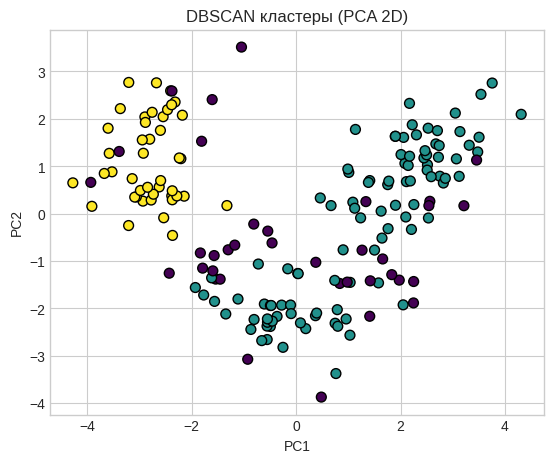

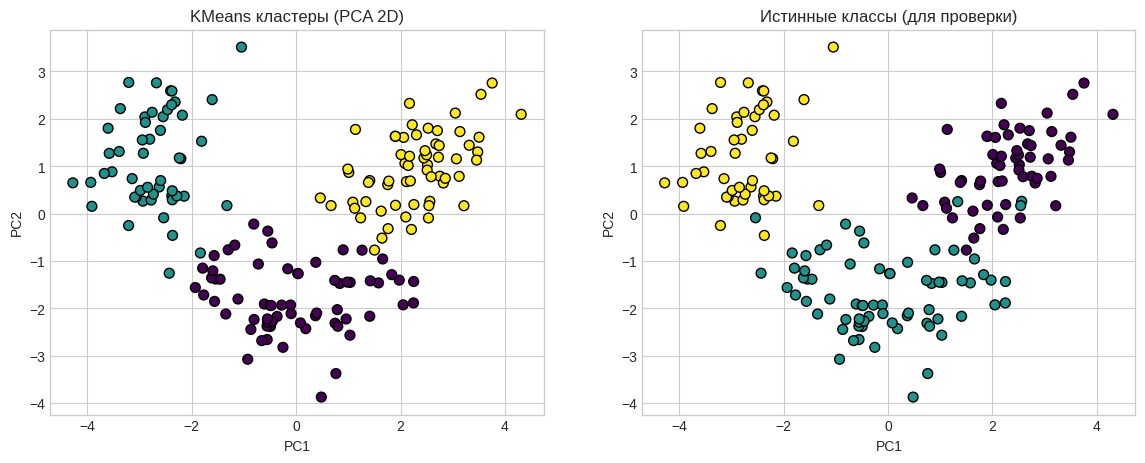

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Настройки графиков
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
np.random.seed(42)


# Понижаем размерность до 2D для визуализации
pca = PCA(n_components=2, random_state=42)
X_wine_pca = pca.fit_transform(X_scaled)

# DBSCAN
labels = DBSCAN(eps=2.4, min_samples=5).fit_predict(X_scaled)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels, cmap='viridis', s=50, edgecolor='k')
plt.title('DBSCAN кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

# KMeans
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=labels_km, cmap='viridis', s=50, edgecolor='k')
plt.title('KMeans кластеры (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 2, 2)
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_true, cmap='viridis', s=50, edgecolor='k')
plt.title('Истинные классы (для проверки)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## Silhouette Score (коэффициент силуэта)

Это **внутренняя метрика качества кластеризации** — ей не нужны «правильные» метки классов, она считает только по данным и полученным кластерам.

### Что измеряет
Для каждой точки она смотрит:
- $a$ — среднее расстояние до других точек **в своём кластере** (насколько точка «своя»);
- $b$ — минимальное среднее расстояние до точек **в любом другом кластере** (насколько она ближе к чужому кластеру).

И считает силуэт для точки:  
$s = \frac{b - a}{\max(a, b)}$

Потом берёт среднее по всем точкам — это и есть `silhouette_score`.

### Как интерпретировать (шкала от −1 до 1)
- **≈ 1**: точка явно принадлежит своему кластеру и далека от других — кластеры компактные и хорошо разделены.
- **≈ 0**: точка на границе двух кластеров — разделение нечёткое.
- **< 0**: точка, скорее всего, попала не туда — её ближе к другому кластеру.

В кластеризации стремятся к значениям **0.3–0.5 и выше** — это уже неплохой результат.

### Важные нюансы для практики
- **Шум (метка −1 у DBSCAN) нельзя включать в расчёт.** В `sklearn` при наличии −1 будет ошибка, поэтому перед расчётом убирают шумовые точки: `silhouette_score(X[mask], labels[mask])`.
- Метрика «любит» компактные, примерно одинаковые по размеру кластеры. Поэтому на данных с разной плотностью (как в DBSCAN) силуэт может быть скромным, даже если кластеры осмысленные.
- Это хороший критерий для **подбора гиперпараметров** (например, $k$ в KMeans или $eps$ в DBSCAN): считают силуэт для разных вариантов и берут тот, где он выше.

---

## Adjusted Rand Index (ARI)

Это **внешняя метрика**: она сравнивает разбиение на кластеры, которое дала модель, с «эталонным» разбиением (например, с настоящими метками классов). В случае Wine это сравнение кластеров DBSCAN с реальными сортами вин.

### Что делает
Считает, насколько совпадают пары точек: если две точки в эталоне в одном классе, а модель тоже поместила их в один кластер — это «совпадение». ARI учитывает, что некоторые совпадения могут возникать случайно, и **корректирует оценку на случайность**.

Формула (упрощённо):  
$\text{ARI} = \frac{\text{RI} - \text{ожидаемый RI при случайном разбиении}}{\max(\text{RI}) - \text{ожидаемый RI}}$

### Как интерпретировать
- **1.0**: полное совпадение разбиений.
- **0.0**: совпадение не лучше, чем у случайного разбиения.
- **Отрицательные значения**: хуже случайного (бывает редко).

На практике:
- **> 0.5**: хорошее согласование;
- **0.3–0.5**: умеренное (часто бывает у DBSCAN на реальных данных);
- **< 0.2**: почти нет связи с эталоном.

### Нюансы
- ARI **не требует**, чтобы названия кластеров совпадали: он смотрит на пары объектов, а не на метки.
- Можно использовать даже если модель выделяет другое число кластеров, чем классов в эталоне.
- В отличие от силуэта, ARI **учитывает шум**: если DBSCAN пометил точки как −1, это влияет на ARI — и это правильно, потому что мы честно говорим, что не смогли их отнести к кластерам.

---

## Как это выглядит в контексте твоего DBSCAN на Wine


- `silhouette_score ≈ 0.33` говорит: «кластеры не идеальные, но в среднем точки ближе к своим, чем к чужим».
- `adjusted_rand_score ≈ 0.42` говорит: «разбиение DBSCAN умеренно согласуется с реальными сортами, это не случайность».
